# Modelo 1: Intenção da pergunta (LarOuAyê)
**Disciplina:** Artificial Intelligence & Chatbot

**Objetivo:** dizer em qual assunto jurídico cai a dúvida do cidadão (matrícula, escritura, contrato, financiamento, FGTS, impostos, leilão, imóvel usado, fraude) ou se está **fora do escopo**.

**Regra do projeto:** *a IA identifica, o Java decide, o conteúdo jurídico fundamenta.* Este modelo **nunca escreve a resposta**.

> **Origem e limites dos dados (registrar no relatório).** As frases foram **escritas pelo grupo/assistente** como amostras sintéticas
> de perguntas reais sobre compra do primeiro imóvel. **Não houve coleta de usuários.** O conjunto de **teste** foi escrito à parte,
> com redação diferente, e **nunca recebe aumento de dados**. Por serem poucas frases, a acurácia é uma **estimativa otimista**:
> perguntas reais de cidadãos terão mais variação, erros de digitação e gírias.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # permite importar larouaye_ia
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from larouaye_ia import nucleo
pd.set_option('display.max_colwidth', 90)

## 1. Análise exploratória

In [2]:
treino, teste = nucleo.carregar('intencao')
print('treino:', treino.shape, '| teste:', teste.shape)
treino.sample(6, random_state=1)

treino: (1476, 2) | teste: (98, 2)


,texto,rotulo
575,pode me ajudar por onde comeco para financiar minha casa pode explicar,FINANCIAMENTO
390,Minha duvida: Qual o horario do jogo do meu time?,FORA_DO_ESCOPO
826,Bom dia! Passo a passo do financiamento imobiliario,FINANCIAMENTO
341,"Comprei casa de familia e nao fizeram inventario, e agora?",IMOVEL_USADO
984,"por favor, o imovel esta em nome de pessoa falecida, posso comprar",IMOVEL_USADO
729,"Ola, Por onde comeco para financiar minha casa? obrigado",FINANCIAMENTO


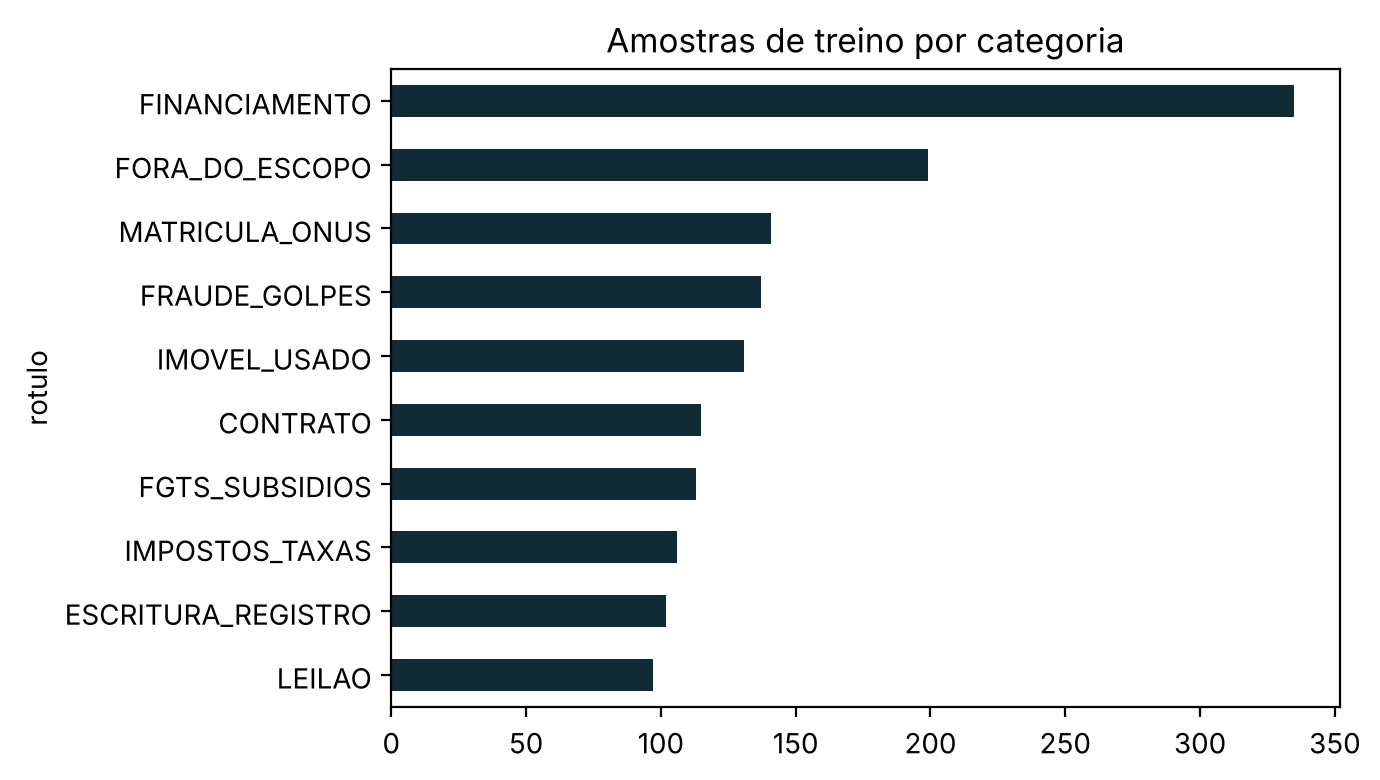

rotulo
FINANCIAMENTO         335
FORA_DO_ESCOPO        199
MATRICULA_ONUS        141
FRAUDE_GOLPES         137
IMOVEL_USADO          131
CONTRATO              115
FGTS_SUBSIDIOS        113
IMPOSTOS_TAXAS        106
ESCRITURA_REGISTRO    102
LEILAO                 97
Name: count, dtype: int64

In [3]:
contagem = treino.rotulo.value_counts()
contagem.sort_values().plot(kind='barh', figsize=(7,4), color='#102b35')
plt.title('Amostras de treino por categoria'); plt.tight_layout(); plt.show()
contagem

In [4]:
print('Tamanho médio da pergunta (letras):', round(treino.texto.str.len().mean(), 1))
print('Categorias:', treino.rotulo.nunique())
print('Nulos:', int(treino.isna().sum().sum()), '| duplicadas:', int(treino.texto.duplicated().sum()))

Tamanho médio da pergunta (letras): 56.0
Categorias: 10
Nulos: 0 | duplicadas: 0


## 2. Pré-processamento e modelo
- **TF-IDF de caracteres (2 a 5)**: aguenta erro de digitação e variações (ex.: *imovel* / *imóvel*), e `strip_accents` ignora acentos.
- **Regressão Logística**: dá **probabilidade** por categoria, que usamos como confiança.

In [5]:
pipe = nucleo.pipeline_intencao()
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",'unicode'
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'char_wb'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(2, ...)"
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode

In [6]:
res = nucleo.treinar_e_avaliar('intencao', pipe)
print('Acurácia no TESTE :', res['acuracia_teste'])
print('F1 macro no TESTE:', res['f1_macro_teste'])

Acurácia no TESTE : 1.0
F1 macro no TESTE: 1.0


## 3. Avaliação detalhada

In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
previsto = pipe.predict(teste.texto)
print(classification_report(teste.rotulo, previsto, zero_division=0))

                    precision    recall  f1-score   support

          CONTRATO       1.00      1.00      1.00         8
ESCRITURA_REGISTRO       1.00      1.00      1.00         8
    FGTS_SUBSIDIOS       1.00      1.00      1.00        10
     FINANCIAMENTO       1.00      1.00      1.00        18
    FORA_DO_ESCOPO       1.00      1.00      1.00        10
     FRAUDE_GOLPES       1.00      1.00      1.00         8
      IMOVEL_USADO       1.00      1.00      1.00        10
    IMPOSTOS_TAXAS       1.00      1.00      1.00         8
            LEILAO       1.00      1.00      1.00         8
    MATRICULA_ONUS       1.00      1.00      1.00        10

          accuracy                           1.00        98
         macro avg       1.00      1.00      1.00        98
      weighted avg       1.00      1.00      1.00        98



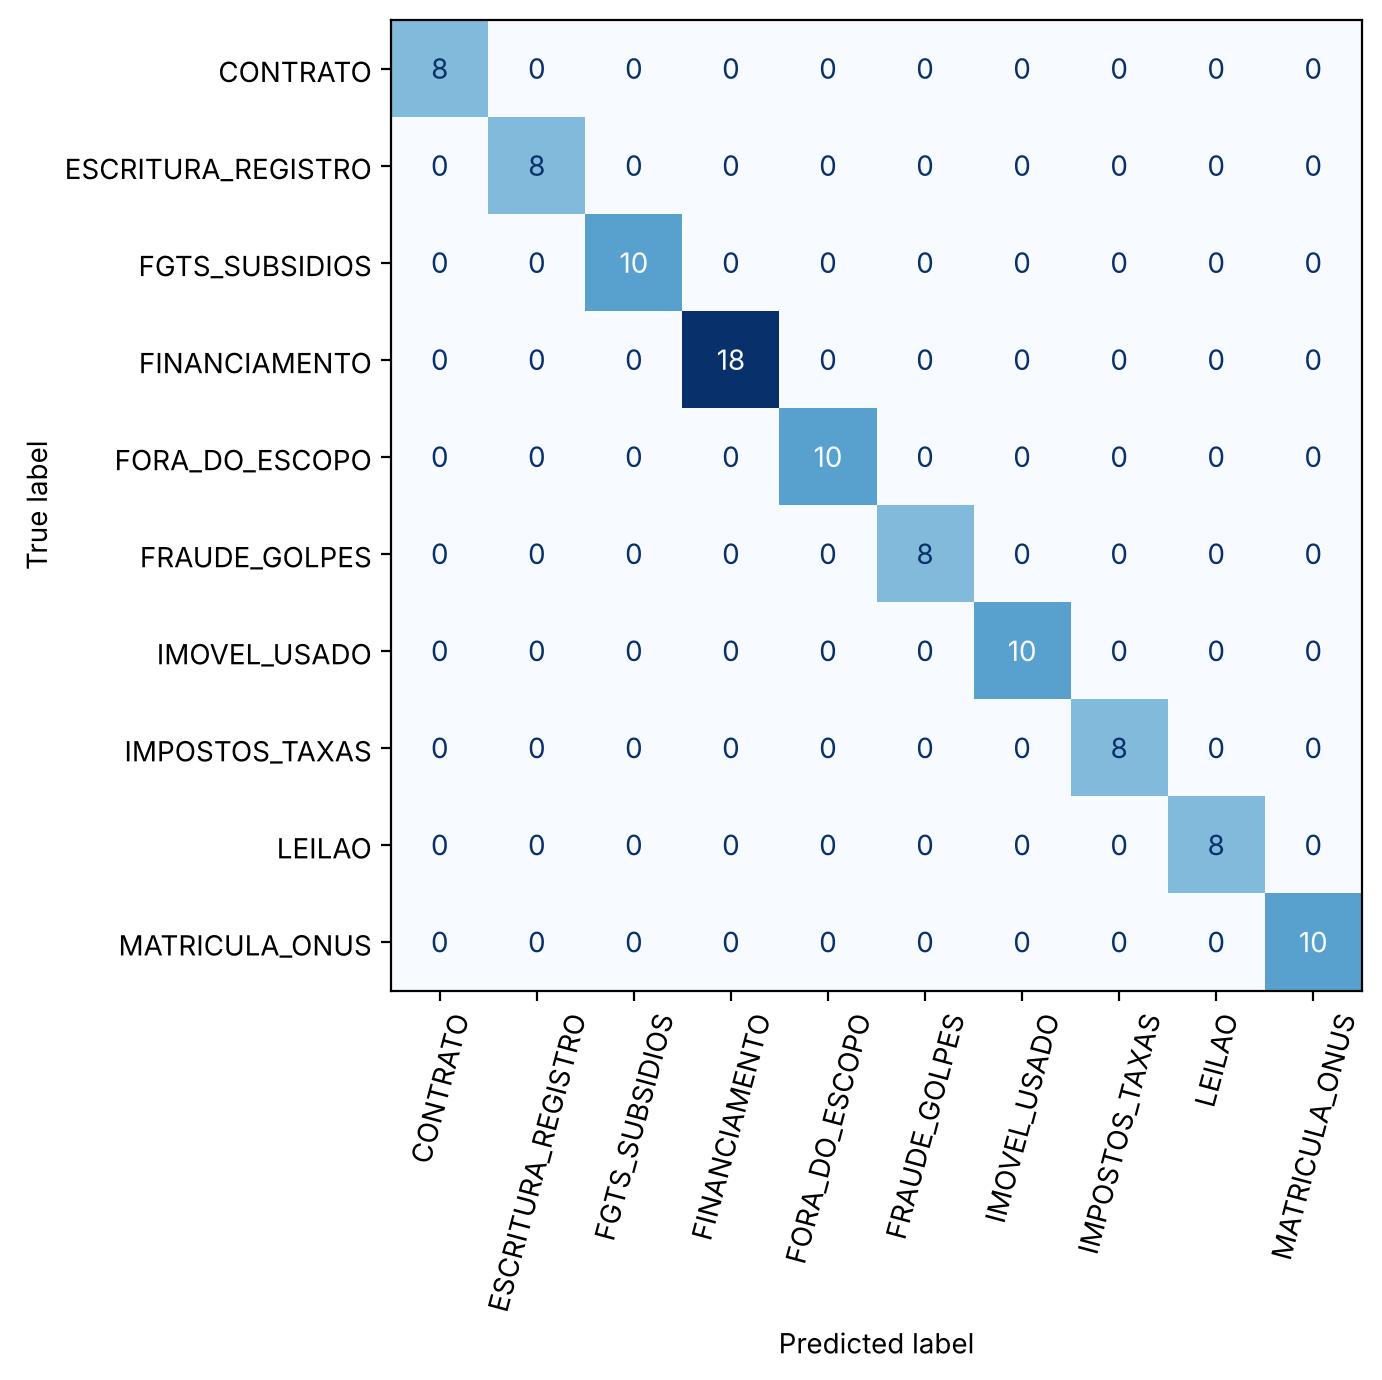

In [8]:
fig, ax = plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay.from_predictions(teste.rotulo, previsto, xticks_rotation=75, cmap='Blues', ax=ax, colorbar=False)
plt.tight_layout(); plt.show()

In [9]:
erros = teste.assign(previsto=previsto, confianca=pipe.predict_proba(teste.texto).max(axis=1).round(2))
erros[erros.rotulo != erros.previsto]

,texto,rotulo,previsto,confianca


## 4. Limiares de confiança (regra de decisão)
O modelo só **responde** com confiança alta. Entre os limiares, o sistema **pergunta** qual assunto a pessoa quer. Abaixo, diz que **não entendeu**.

In [10]:
from larouaye_ia import servico
prob = pipe.predict_proba(teste.texto); conf = prob.max(axis=1); acertou = (pipe.classes_[prob.argmax(axis=1)] == teste.rotulo.values)
print(f'Limiar de resposta direta: {servico.LIMIAR_RESPONDER} | de esclarecimento: {servico.LIMIAR_ESCLARECER}')
resp = conf >= servico.LIMIAR_RESPONDER
print('Respondidas direto:', int(resp.sum()), 'de', len(conf))
print('Acertos entre as respondidas direto:', round(float(acertou[resp].mean()), 3))
print('Erros que ficaram abaixo do limiar (seguros):', int((~acertou & ~resp).sum()), 'de', int((~acertou).sum()))

Limiar de resposta direta: 0.7 | de esclarecimento: 0.3
Respondidas direto: 86 de 98
Acertos entre as respondidas direto: 1.0
Erros que ficaram abaixo do limiar (seguros): 0 de 0


## 5. Teste cego e perguntas reais do Instagram
O teste de desenvolvimento (seção 2) **guiou ajustes** do treino, então já não é independente (por isso chega perto de 100%). Os dois conjuntos abaixo são as medidas mais honestas:
- **Teste cego**: 55 frases escritas **depois** do ajuste final e usadas para medir.
- **Validação real**: 11 perguntas **reais** de pessoas do Instagram do projeto, que **nunca entram no treino**. Atenção: o autor das frases de treino já conhecia essas perguntas, então o resultado é otimista.

In [11]:
import sys; sys.path.insert(0, str(Path.cwd().parent / 'treino'))
from treino import avaliar_intencao
resultado = avaliar_intencao.main(nucleo.MODELOS / 'modelo_intencao.joblib')
pd.DataFrame(resultado).T

teste_desenvolvimento        {'n': 98, 'acuracia': 1.0, 'responde_direto': 0.878, 'acerto_quando_responde': 1.0, 'erros_com_confianca_alta': 0, 'pede_esclarecimento': 11, 'nao_reconhecidas': 1}
teste_cego                   {'n': 55, 'acuracia': 0.927, 'responde_direto': 0.891, 'acerto_quando_responde': 0.98, 'erros_com_confianca_alta': 1, 'pede_esclarecimento': 5, 'nao_reconhecidas': 1}
validacao_real_instagram     {'n': 11, 'acuracia': 1.0, 'responde_direto': 1.0, 'acerto_quando_responde': 1.0, 'erros_com_confianca_alta': 0, 'pede_esclarecimento': 0, 'nao_reconhecidas': 0}


,n,acuracia,responde_direto,acerto_quando_responde,erros_com_confianca_alta,pede_esclarecimento,nao_reconhecidas
teste_desenvolvimento,98.0,1.000,0.878,1.00,0.0,11.0,1.0
teste_cego,55.0,0.927,0.891,0.98,1.0,5.0,1.0
validacao_real_instagram,11.0,1.000,1.000,1.00,0.0,0.0,0.0


In [12]:
cego = pd.read_csv(nucleo.DADOS / 'intencao_teste_cego.csv')
prev = pipe.predict(cego.texto); conf_c = pipe.predict_proba(cego.texto).max(axis=1).round(2)
cego.assign(previsto=prev, confianca=conf_c)[prev != cego.rotulo.values]

,texto,rotulo,previsto,confianca
9,se eu quitar o imovel do programa habitacional antes de 5 anos o que acontece?,FGTS_SUBSIDIOS,FINANCIAMENTO,0.36
10,posso pagar a entrada com o dinheiro do fundo de garantia?,FGTS_SUBSIDIOS,FINANCIAMENTO,0.37
30,quanto custa o registro do imovel no cartorio?,ESCRITURA_REGISTRO,IMPOSTOS_TAXAS,0.78
45,como evitar cair em golpe quando for comprar casa?,FRAUDE_GOLPES,IMOVEL_USADO,0.32


## 6. Exemplos reais (incluindo o caso de fraude do corretor)

In [13]:
exemplos = ['O corretor alterou meu IRRF e colocou minha esposa como dependente', 'Como sei se o imóvel tem escritura?', 'Posso usar FGTS na entrada?', 'Quero comprar um tênis', 'oi']
linhas = []
for q in exemplos:
    p = pipe.predict_proba([q])[0]; i = p.argmax(); linhas.append((q, pipe.classes_[i], round(float(p[i]), 2)))
pd.DataFrame(linhas, columns=['pergunta','categoria','confianca'])

,pergunta,categoria,confianca
0,O corretor alterou meu IRRF e colocou minha esposa como dependente,FRAUDE_GOLPES,0.98
1,Como sei se o imóvel tem escritura?,ESCRITURA_REGISTRO,0.98
2,Posso usar FGTS na entrada?,FGTS_SUBSIDIOS,0.99
3,Quero comprar um tênis,FORA_DO_ESCOPO,0.66
4,oi,FORA_DO_ESCOPO,0.63


## 7. Exportação
O modelo é salvo em `.joblib` e carregado pela API Flask (`app.py`).

In [14]:
caminho = nucleo.exportar(pipe, 'intencao'); print('salvo em', caminho.name, '|', round(caminho.stat().st_size/1024), 'KB')

salvo em modelo_intencao.joblib | 549 KB


## 7. Limitações e riscos
- Poucas frases sintéticas: reavaliar com perguntas reais antes de usar fora da apresentação.
- Confiança alta **não** significa resposta jurídica correta: o texto vem do catálogo revisado.
- O assunto *fora do escopo* é uma categoria treinada, mas assuntos muito diferentes podem escapar: o limiar protege.
- Não há dados pessoais no conjunto de treino.